In [1]:
import pandas as pd
url = "../data/clean/bookworms_cleaned_data_file.csv"
df = pd.read_csv(url, dtype={"isbn": str, "isbn13": str})
#making sure isbn and isbn13 are imported as str
df.head()

,bookID,title,authors,average_rating,isbn,isbn13,language_code,num_pages,ratings_count,text_reviews_count,publication_date,publisher,publication_year
0,1,Harry Potter and the Half-Blood Prince (Harry ...,J.K. Rowling,4.57,0439785960,9780439785969,eng,652.0,2095690,27591,9/16/2006,Scholastic Inc.,2006
1,2,Harry Potter and the Order of the Phoenix (Har...,J.K. Rowling,4.49,0439358078,9780439358071,eng,870.0,2153167,29221,9/1/2004,Scholastic Inc.,2004
2,4,Harry Potter and the Chamber of Secrets (Harry...,J.K. Rowling,4.42,0439554896,9780439554893,eng,352.0,6333,244,11/1/2003,Scholastic,2003
3,5,Harry Potter and the Prisoner of Azkaban (Harr...,J.K. Rowling,4.56,043965548X,9780439655484,eng,435.0,2339585,36325,5/1/2004,Scholastic Inc.,2004
4,8,Harry Potter Boxed Set Books 1-5 (Harry Potte...,J.K. Rowling,4.78,0439682584,9780439682589,eng,2690.0,41428,164,9/13/2004,Scholastic,2004


In [2]:
# Which books should Bookworms prioritize for recommendations? 
# Specifically, which books should be considered for Popular Favourites, Highly Rated Short Reads, and Hidden-Gem Candidates?

# Collections:
# Popular Favourites: average_rating >= 4.0, ratings_count ≥ 10,000, num_pages any
# Highly Rated Short Reads:	average_rating >= 4.0, ratings_count ≥ 500, num_pages 3–100
# Hidden-Gem Candidates: average_rating >= 4.2, ratings_count 100–999, num_pages any
# Popular Classics: average_rating >= 4.0, publication date < 1976

english = df["language_code"] == "eng" #focusing on eng
df["collections"] = "" #new column

# Popular Favourites
popular_fav = (
    english 
    & (df["average_rating"] >= 4.0) #books with avg above 4.0
    & (df["ratings_count"] >= 10000) #more than 10000 ratings
)

df.loc[popular_fav, "collections"] += "Popular Favourites / "
print("Popular Favourites:", popular_fav.sum())

# Recommended Short Reads

short_reads = (
    english
    & (df["average_rating"] >= 4.0) #books with avg above 4.0 
    & (df["ratings_count"] >= 500) #more than 500 ratings
    & (df["num_pages"] > 2) #more than 2 pages
    & (df["num_pages"] <= 100) #up to 100 pages
)

df.loc[short_reads, "collections"] += "Recommended Short Reads / "
print("Recommended Short Reads:", short_reads.sum())

#Hidden Gems Candidates

hidden_gems = (
    english
    & (df["average_rating"] >= 4.5) #books with avg above 4.5
    & (df["ratings_count"] >= 100) #more than 100 ratings
    & (df["ratings_count"] <= 999) #less than 1000 ratings
)

df.loc[hidden_gems, "collections"] += "Hidden-Gem Candidates / "
print("Hidden-Gem Candidate:", hidden_gems.sum())

# Popular classics
popular_classics = (
    english &
    (df["average_rating"] >= 4.0) & #books with avg above 4.0
    (df["publication_year"] < 1976) #publication year older than 50 years
)

df.loc[popular_classics, "collections"] += "Popular Classics / "
print("Popular Classics:", popular_classics.sum())

df["collections"] = df["collections"].str.strip(" /")

Popular Favourites: 972
Recommended Short Reads: 186
Hidden-Gem Candidate: 45
Popular Classics: 96


In [3]:
#Inspect top 20 of Popular Favourites
df.loc[popular_fav, ["title", "average_rating", "ratings_count", "collections"]].sort_values("average_rating", ascending=False).head(20)

,title,average_rating,ratings_count,collections
6585,The Complete Calvin and Hobbes,4.82,32213,Popular Favourites
4,Harry Potter Boxed Set Books 1-5 (Harry Potte...,4.78,41428,Popular Favourites
6587,It's a Magical World (Calvin and Hobbes #11),4.76,23875,Popular Favourites
6,Harry Potter Collection (Harry Potter #1-6),4.73,28242,Popular Favourites
6588,Homicidal Psycho Jungle Cat (Calvin and Hobbes...,4.72,15365,Popular Favourites
6589,The Days Are Just Packed,4.69,20308,Popular Favourites
6292,The Absolute Sandman Volume One,4.65,15640,Popular Favourites
6586,The Calvin and Hobbes Tenth Anniversary Book,4.63,49122,Popular Favourites
72,The Lord of the Rings: The Art of the Fellowsh...,4.59,26153,Popular Favourites
21,J.R.R. Tolkien 4-Book Boxed Set: The Hobbit an...,4.59,101233,Popular Favourites


In [4]:
#Inspect top 20 of Recommended Short Reads
df.loc[short_reads, ["title", "average_rating", "ratings_count", "num_pages", "collections"]].sort_values("average_rating", ascending=False).head(20)

,title,average_rating,ratings_count,num_pages,collections
6591,Calvin and Hobbes: Sunday Pages 1985-1995: An ...,4.71,3613,96.0,Recommended Short Reads
165,The Gettysburg Address,4.53,5239,32.0,Recommended Short Reads
7510,The Return of the King (The Lord of the Rings ...,4.53,3529,16.0,Recommended Short Reads
4248,The Lord of the Rings: The Two Towers: Visual ...,4.51,4524,72.0,Recommended Short Reads
1705,Love,4.46,1333,43.0,Recommended Short Reads
10822,The Monster at the End of this Book,4.44,114297,32.0,Popular Favourites / Recommended Short Reads
1536,The Christmas Story,4.43,1304,24.0,Recommended Short Reads
5095,The Kissing Hand,4.43,57737,32.0,Popular Favourites / Recommended Short Reads
4050,The Story of Ruby Bridges,4.43,11403,32.0,Popular Favourites / Recommended Short Reads
9859,The Shawshank Redemption,4.43,725,96.0,Recommended Short Reads


In [5]:
#Inspect top 20 of Hidden Gem Candidates
df.loc[hidden_gems, ["title", "average_rating", "ratings_count", "collections"]].sort_values("average_rating", ascending=False).head(20)

,title,average_rating,ratings_count,collections
1847,Early Color,4.73,144,Hidden-Gem Candidates
8928,Elliott Erwitt: Snaps,4.72,102,Hidden-Gem Candidates
10933,The Price of the Ticket: Collected Nonfiction ...,4.70,404,Hidden-Gem Candidates
7040,The Sibley Field Guide to Birds of Western Nor...,4.69,730,Hidden-Gem Candidates
7101,The Gospel According to Luke,4.64,169,Hidden-Gem Candidates
3656,The Collected Autobiographies of Maya Angelou,4.63,991,Hidden-Gem Candidates
4811,The Feynman Lectures on Physics Vol 3,4.63,716,Hidden-Gem Candidates
6590,The Calvin And Hobbes: Tenth Anniversary Book,4.63,303,Hidden-Gem Candidates
5346,The World of Peter Rabbit (Original Peter Rabb...,4.62,220,Hidden-Gem Candidates
4829,The Complete C.S. Lewis Signature Classics,4.61,925,Hidden-Gem Candidates


In [6]:
#Inspect top 20 of Popular Classics
df.loc[popular_classics, ["title", "average_rating", "collections", "publication_year"]].sort_values("average_rating", ascending=False).head(20)

,title,average_rating,collections,publication_year
4931,Bulgakov's the Master and Margarita: The Text ...,5.00,Popular Classics,1975
10052,The Valley of Vision: A Collection of Puritan ...,4.54,Popular Classics,1975
335,The Power Broker: Robert Moses and the Fall of...,4.51,Popular Favourites / Popular Classics,1975
5562,The Penguin Companion to European Literature,4.50,Popular Classics,1969
2633,The Orwell Reader: Fiction Essays and Reportage,4.38,Popular Classics,1961
2251,The Poppy Seed Cakes,4.37,Popular Classics,1964
7896,The Pound Era,4.37,Popular Classics,1973
1779,The Collected Poems of Wilfred Owen,4.34,Popular Classics,1965
6527,Discourses Books 3-4. The Enchiridion (Loeb C...,4.34,Popular Classics,1928
10370,Love Poems and Sonnets,4.34,Popular Classics,1957


In [7]:
# H1 - Ratings and popularity: Books with more Goodreads ratings tend to have higher average ratings.

rated_books = df.dropna(subset=["average_rating"]) #checking only this column for non-values
has_ratings = rated_books["ratings_count"] > 0
rated_books = rated_books[has_ratings]

print("Total records:", len(df))
print("Records with ratings:", len(rated_books))
#There are 11042 books with ratings above 0

# Finding the middle value of the rating counts
median_count = rated_books["ratings_count"].median()

# Divide editions into two groups
lower_group = rated_books[rated_books["ratings_count"] <= median_count]
higher_group = rated_books[rated_books["ratings_count"] > median_count]

# Compare their average scores
print("Rating-count cutoff:", median_count)

print("\nLower-count group:", len(lower_group), "editions")
print("Mean score:", lower_group["average_rating"].mean().round(3))

print("\nHigher-count group:", len(higher_group), "editions")
print("Mean score:", higher_group["average_rating"].mean().round(3))

Total records: 11123
Records with ratings: 11042
Rating-count cutoff: 764.5

Lower-count group: 5521 editions
Mean score: 3.923

Higher-count group: 5521 editions
Mean score: 3.963


In [8]:
#CONCLUSION H1

# Editions with more Goodreads ratings had a slightly higher mean score (3.963) than those with fewer ratings (3.923).
# The difference was only 0.04 points out of 5, providing limited descriptive support for H1. 
# For Bookworms, rating count alone offers little guidance on reader satisfaction, so recommendations should consider
# both average rating and number of ratings.

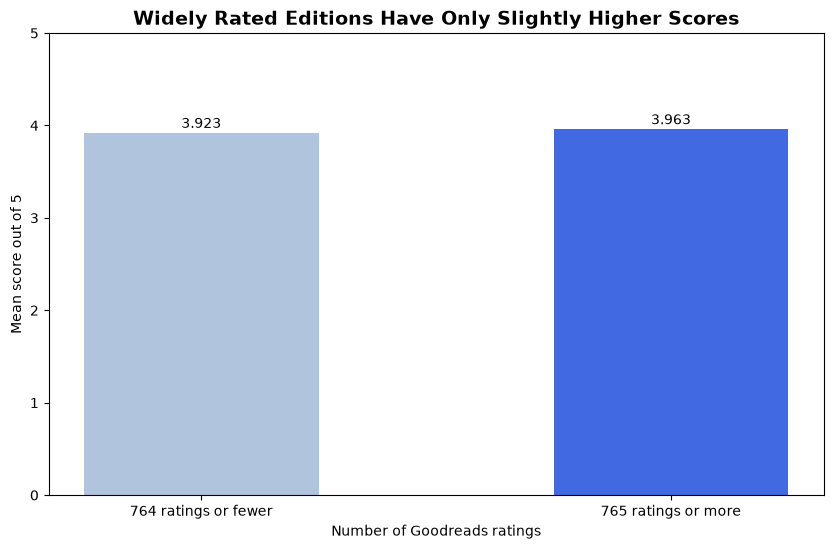

In [9]:
import matplotlib.pyplot as plt

# For the graph
labels = ["764 ratings or fewer", "765 ratings or more"]

scores = [lower_group["average_rating"].mean(), higher_group["average_rating"].mean()]

# Create the bar chart
plt.figure(figsize=(10, 6))
plt.bar(labels, scores, color=["lightsteelblue", "royalblue"], width=0.5)

# Show each mean above its bar
for i, score in enumerate(scores):
    plt.text(i, score + 0.05, f"{score:.3f}", ha="center")

plt.title(
    "Widely Rated Editions Have Only Slightly Higher Scores",
    fontsize=14,
    fontweight="bold"
)
plt.xlabel("Number of Goodreads ratings")
plt.ylabel("Mean score out of 5")

# Show the full rating scale and saving the graph
plt.ylim(0, 5)

plt.savefig("h1_ratings_and_popularity.png", dpi=200, bbox_inches="tight")
plt.show()

In [10]:
# H2 - Author consistency: Some authors with multiple books consistently receive higher ratings than the overall book population.

rated_books["authors"].value_counts().head(20) #20 most frequent authors

authors
Stephen King                   40
P.G. Wodehouse                 40
Rumiko Takahashi               38
Orson Scott Card               35
Agatha Christie                33
Piers Anthony                  30
Mercedes Lackey                29
Sandra Brown                   29
Dick Francis                   28
J.K. Rowling                   25
Margaret Weis/Tracy Hickman    23
Terry Pratchett                23
James Patterson                23
Laurell K. Hamilton            23
Bill Bryson                    21
Gordon Korman                  21
Janet Evanovich                21
Dan Simmons                    21
Alan Dean Foster               21
Gabriel García Márquez         20
Name: count, dtype: int64

In [11]:
author_summary = rated_books.groupby("authors").agg(
    edition_count=("bookID", "count"), #how many books belong to that author
    median_rating=("average_rating", "median"), #the middle score among those editions
    total_ratings=("ratings_count", "sum") #number of ratings across those records
)

author_summary.sort_values("edition_count", ascending=False).head(20) #top 20 authors with the most books

,edition_count,median_rating,total_ratings
authors,,,
P.G. Wodehouse,40,4.165,96053
Stephen King,40,3.965,2985634
Rumiko Takahashi,38,4.235,45292
Orson Scott Card,35,3.840,656554
Agatha Christie,33,3.970,1599571
Piers Anthony,30,3.755,93428
Mercedes Lackey,29,4.030,310832
Sandra Brown,29,3.630,118480
Dick Francis,28,3.985,82544


In [12]:
#Defining a benchmark for comparison
catalogue_median = rated_books["average_rating"].median()
print("Catalogue median rating:", catalogue_median)

Catalogue median rating: 3.96


In [13]:
#authors with median scores above the benchmark

authors_above_catalogue = author_summary[
    (author_summary["edition_count"] >= 3) & #at least 3 books
    (author_summary["total_ratings"] >= 1000) & #at least 1000 ratings
    (author_summary["median_rating"] > catalogue_median) #median above benchmark
]

authors_above_catalogue.sort_values("median_rating", ascending=False).head(20)

,edition_count,median_rating,total_ratings
authors,,,
Bill Watterson,7,4.710,144799
Hayao Miyazaki/Matt Thorn/Kaori Inoue/Joe Yamazaki/Walden Wong/Izumi Evers,3,4.610,5396
Hiromu Arakawa/Akira Watanabe,12,4.570,229591
J.R.R. Tolkien,17,4.500,4776638
Jude Fisher,3,4.500,1698
J.K. Rowling,25,4.490,9265287
Kyoko Hikawa/Yuko Sawada/Freeman Wong,3,4.480,2792
Warren Ellis/Darick Robertson/Rodney Ramos,4,4.455,43962
Stuart McLean,3,4.450,1036


In [14]:
# how consistently do their editions exceed that benchmark

# Copying rated records for the H2 analysis
h2_books = rated_books.copy()

# middle rating across all rated editions
catalogue_median = h2_books["average_rating"].median()

print("Catalogue median:", catalogue_median)

# True = rating scores above the catalogue median; False = rating scores at or below the median
h2_books["above_catalogue"] = (h2_books["average_rating"] > catalogue_median)

# Inspect examples of the comparison
h2_books[["authors", "average_rating", "above_catalogue"]].head(10)

Catalogue median: 3.96


,authors,average_rating,above_catalogue
0,J.K. Rowling,4.57,True
1,J.K. Rowling,4.49,True
2,J.K. Rowling,4.42,True
3,J.K. Rowling,4.56,True
4,J.K. Rowling,4.78,True
5,W. Frederick Zimmerman,3.74,False
6,J.K. Rowling,4.73,True
7,Douglas Adams,4.38,True
8,Douglas Adams,4.38,True
9,Douglas Adams,4.22,True


In [15]:
# Group by author, consider consistent when above benchmark 3 out of 4 times (75%)

consistency = (h2_books.groupby("authors")["above_catalogue"].mean() * 100).round(2)

author_summary["percent_above_catalogue"] = consistency

# Show the same top 20 by edition count, now including consistency
author_summary.sort_values("edition_count", ascending=False).head(20)

,edition_count,median_rating,total_ratings,percent_above_catalogue
authors,,,,
P.G. Wodehouse,40,4.165,96053,85.00
Stephen King,40,3.965,2985634,50.00
Rumiko Takahashi,38,4.235,45292,97.37
Orson Scott Card,35,3.840,656554,17.14
Agatha Christie,33,3.970,1599571,51.52
Piers Anthony,30,3.755,93428,10.00
Mercedes Lackey,29,4.030,310832,72.41
Sandra Brown,29,3.630,118480,24.14
Dick Francis,28,3.985,82544,60.71


In [16]:
# Filtering author entries
consistent_authors = author_summary[
    (author_summary["edition_count"] >= 3) &          # At least 3 editions
    (author_summary["total_ratings"] >= 1000) &       # At least 1000 ratings
    (author_summary["median_rating"] > catalogue_median) &
    (author_summary["percent_above_catalogue"] >= 75) # 75% score above the benchmark
]

print("Qualifying author entries:", len(consistent_authors))

consistent_authors.sort_values("median_rating", ascending=False).head(20).round(2)

Qualifying author entries: 213


,edition_count,median_rating,total_ratings,percent_above_catalogue
authors,,,,
Bill Watterson,7,4.71,144799,100.00
Hayao Miyazaki/Matt Thorn/Kaori Inoue/Joe Yamazaki/Walden Wong/Izumi Evers,3,4.61,5396,100.00
Hiromu Arakawa/Akira Watanabe,12,4.57,229591,100.00
J.R.R. Tolkien,17,4.50,4776638,100.00
J.K. Rowling,25,4.49,9265287,100.00
Kyoko Hikawa/Yuko Sawada/Freeman Wong,3,4.48,2792,100.00
Warren Ellis/Darick Robertson/Rodney Ramos,4,4.46,43962,100.00
Karen Kingsbury/Gary Smalley,5,4.45,81932,100.00
Stuart McLean,3,4.45,1036,100.00


In [17]:
## CONCLUSION H2

# Several credited author entries consistently score above the catalogue median of 3.96.
# Bill Watterson has a median rating of 4.71 across seven editions, J.R.R. Tolkien has 4.50 across 17, and J.K. Rowling has 4.49 across 25.
# Every rated edition in each of these entries exceeds the catalogue median. These authors are candidates for further review for Bookworms’
# recommendations and promotions.

# Results describe the editions present in this dataset.
# Different editions may represent the same work, and entries containing multiple contributor names were assessed together.

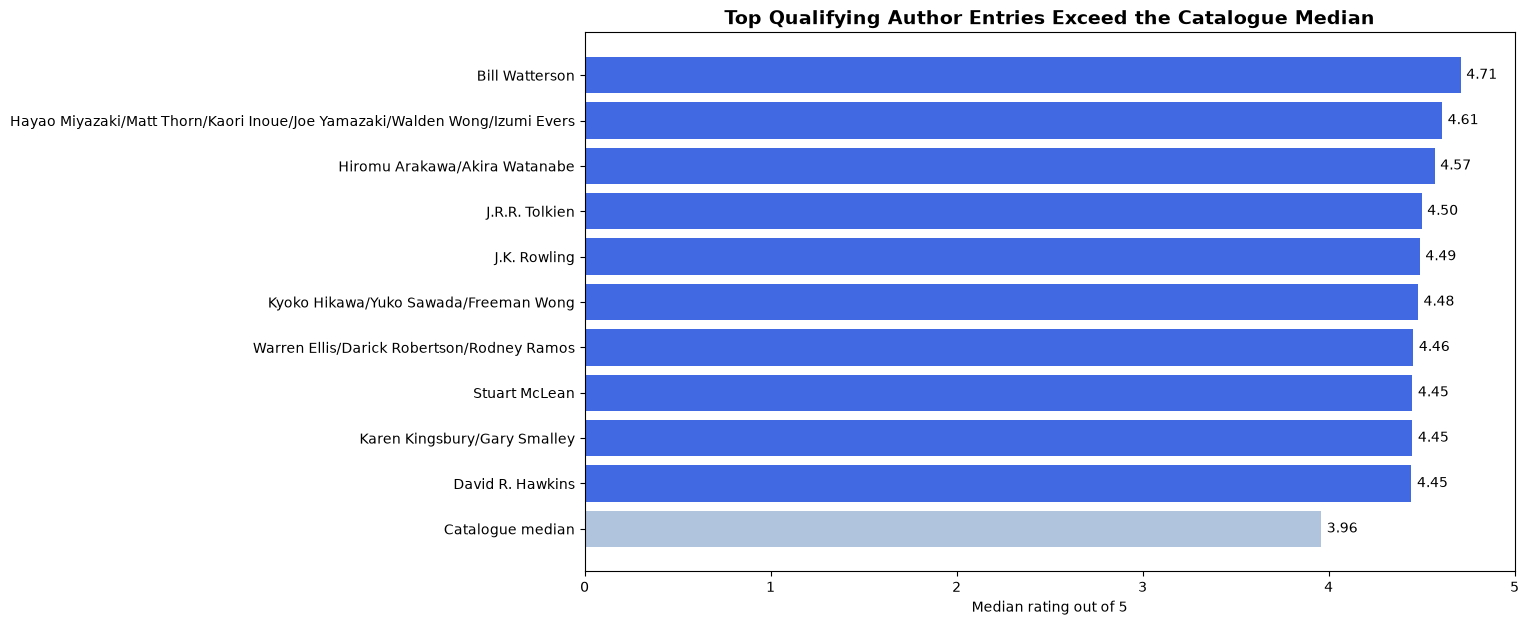

In [18]:
# Select the 10 qualifying entries with the highest median scores
top_authors = consistent_authors.sort_values("median_rating", ascending=False).head(10)

top_authors = top_authors.sort_values("median_rating")

labels = ["Catalogue median"] + top_authors.index.tolist()
scores = [catalogue_median] + top_authors["median_rating"].tolist()

colors = ["lightsteelblue"] + ["royalblue"] * len(top_authors)

plt.figure(figsize=(12, 7))
plt.barh(labels, scores, color=colors)

# Display each median score beside its bar
for i, score in enumerate(scores):
    plt.text(score + 0.03, i, f"{score:.2f}", va="center")

plt.title(
    "Top Qualifying Author Entries Exceed the Catalogue Median",
    fontsize=14,
    fontweight="bold"
)
plt.xlabel("Median rating out of 5")
plt.xlim(0, 5)

plt.savefig("h2_author_consistency.png", dpi=200, bbox_inches="tight")
plt.show()